CBOW Model Trained Successfully!


Enter your interest:  I Love Machine Learning!



Top 5 Recommended Tweets:

Tweet: Rule art image require develop town data. Table every response reason often.
Husband may treat fight everyone. Machine explain performance thing clearly condition wait.
Project against program concern. Behind down from think drug strategy short. Maintain consumer save.
Similarity: 0.992

Tweet: Detail despite effect star clear blue poor. Herself indicate themselves eat conference policy forget.
Three population coach body glass. House national including remember hold.
Similarity: 0.992

Tweet: Buy three raise society. Top fish three may. Notice able mention real west product.
Wish population of year while. Maybe sing know there community. Paper science pattern middle idea beyond.
Woman response about hot long computer three tax. Action detail list.
Similarity: 0.992

Tweet: Prove baby space whom local I hospital. Treat provide series stay agent happy themselves.
Gas cultural big training agent home offer. Human back accept force.
Material until total.

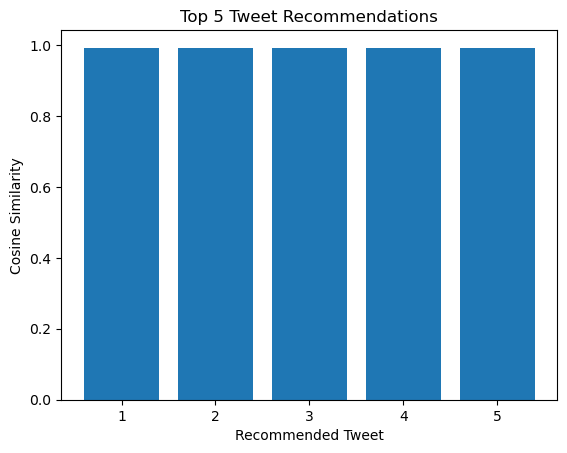

In [2]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt

from gensim.models import Word2Vec
from sklearn.metrics.pairwise import cosine_similarity

# Step 1: Load Dataset
df = pd.read_csv("twitter_dataset.csv")

# Step 2: Clean Text
def clean(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|@\w+|#", "", text)
    text = re.sub(r"[^a-z\s]", "", text)
    return text.split()

df["tokens"] = df["Text"].apply(clean)

# Step 3: Train CBOW Model
model = Word2Vec(
    sentences=df["tokens"].tolist(),
    vector_size=100,
    window=5,
    min_count=1,
    sg=0,
    epochs=10
)

print("CBOW Model Trained Successfully!")

# Step 4: Convert Text into Vector
def get_vector(words):
    vectors = [model.wv[w] for w in words if w in model.wv]

    if len(vectors) == 0:
        return np.zeros(100)

    return np.mean(vectors, axis=0)

# Step 5: Convert All Tweets into Vectors
tweet_vectors = np.array([
    get_vector(words) for words in df["tokens"]
])

# Step 6: Take User Input
user_input = input("Enter your interest: ")

user_tokens = clean(user_input)
user_vector = get_vector(user_tokens)

# Step 7: Calculate Cosine Similarity
if not any(word in model.wv for word in user_tokens):
    print("No matching words found in vocabulary.")
else:
    similarity = cosine_similarity(
        [user_vector], tweet_vectors
    )[0]

    # Step 8: Find Top 5 Recommendations
    top_indices = np.argsort(similarity)[-5:][::-1]

    print("\nTop 5 Recommended Tweets:\n")

    for i in top_indices:
        print("Tweet:", df["Text"].iloc[i])
        print("Similarity:", round(similarity[i], 3))
        print()

    # Step 9: Plot Graph
    scores = similarity[top_indices]

    plt.bar(range(1, 6), scores)
    plt.xlabel("Recommended Tweet")
    plt.ylabel("Cosine Similarity")
    plt.title("Top 5 Tweet Recommendations")
    plt.xticks(range(1, 6))
    plt.show()